# REL301m Assignment 2 — ADBE end-to-end

Notebook chạy trọn quy trình từ dữ liệu đến kết quả:

1. Dữ liệu ADBE và chia train/test
2. Luật giao dịch, môi trường (action, observation, reward, terminated)
3. Baseline
4. Huấn luyện CEM chỉ trên 8 năm train
5. Đối chiếu model vừa train với model đã nộp (tham số phải trùng hoàn toàn)
6. Đánh giá train/test bằng model đã lưu
7. Bonus: test 2 năm bằng load/predict
8. Replay trên giai đoạn khác, kiểm chứng tự động, kết quả cuối

Chạy được ở hai nơi:

- **Kaggle:** đính kèm dataset `adbe-rel301m-cem` (chứa code `adbe_rl/`, dữ liệu và model đã nộp) rồi Run All. Notebook tự tìm code trong `/kaggle/input`, và ghi kết quả vào `/kaggle/working/outputs`.
- **Máy cá nhân:** mở notebook từ thư mục project. Kết quả ghi vào `outputs/end_to_end/`, không ghi đè model đã nộp trong `outputs/consecutive/`.

Với ngân sách đầy đủ, phần huấn luyện mất khoảng 3–5 phút trên CPU; đặt `QUICK = True` để chạy thử khoảng 20 giây. Notebook không cần GPU hay Internet.

In [1]:
import hashlib
import json
import sys
import time
from pathlib import Path

ON_KAGGLE = Path('/kaggle/input').is_dir()
if ON_KAGGLE:
    # Code, data and submitted models come from the attached (read-only) dataset.
    package = next(Path('/kaggle/input').rglob('adbe_rl/__init__.py'))
    sys.path.insert(0, str(package.parent.parent))

import matplotlib.pyplot as plt
import pandas as pd

from adbe_rl.broker import ACTIONS
from adbe_rl.config import OUTPUT_DIR, load_config, track_dir
from adbe_rl.env import OBSERVATION_NAMES, TradingEnv, run_episode
from adbe_rl.evaluation import LABELS, evaluate_track, history_name, replay_windows
from adbe_rl.market import FEATURE_NAMES, load_prices, load_track
from adbe_rl.policies import PenaltyAwareHold, load_policy
from adbe_rl.training import train_track
from adbe_rl.verify import verify

TRACK = 'consecutive'                 # bản chính: train 2008–2016, test 2016–2018 ('dotcom': 1990–1998 / 1998–2000)
QUICK = False                         # True: ngân sách CEM nhỏ, kết quả khác bản đã nộp
# Thư mục ghi kết quả của lần chạy này (dataset trên Kaggle là chỉ đọc).
OUTPUT = Path('/kaggle/working/outputs') if ON_KAGGLE else OUTPUT_DIR / 'end_to_end'

config = load_config().quick() if QUICK else load_config()
print('Code:', OUTPUT_DIR.parent, '| ghi kết quả vào:', OUTPUT)
COLORS = ['#2a78d6', '#eb6834', '#1baf7a']
REFERENCE = '#8a8f98'
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})

Code: /tmp/claude-0/-home-claude/59bdde93-07fa-5178-bea0-427f9508acb0/scratchpad/work | ghi kết quả vào: /tmp/claude-0/-home-claude/59bdde93-07fa-5178-bea0-427f9508acb0/scratchpad/work/outputs/end_to_end


## 1. Dữ liệu

Giá OHLC theo ngày của ADBE từ Yahoo Finance, đã điều chỉnh theo các lần chia tách cổ phiếu.

In [2]:
prices = load_prices(config.data_file)
print(f'{len(prices):,} phiên: {prices.Date.iloc[0].date()} → {prices.Date.iloc[-1].date()}')
prices.tail()

10,114 phiên: 1986-08-13 → 2026-10-06


,Date,Open,High,Low,Close,Volume
10109,2026-09-30,233.699997,240.839996,231.949997,239.940002,4516500
10110,2026-10-01,245.929993,248.300003,237.789993,241.279999,4762900
10111,2026-10-02,243.050003,243.919998,236.880005,237.690002,3113100
10112,2026-10-05,238.679993,241.000000,235.509995,238.789993,3292400
10113,2026-10-06,240.869995,240.869995,236.770004,238.119995,2641800


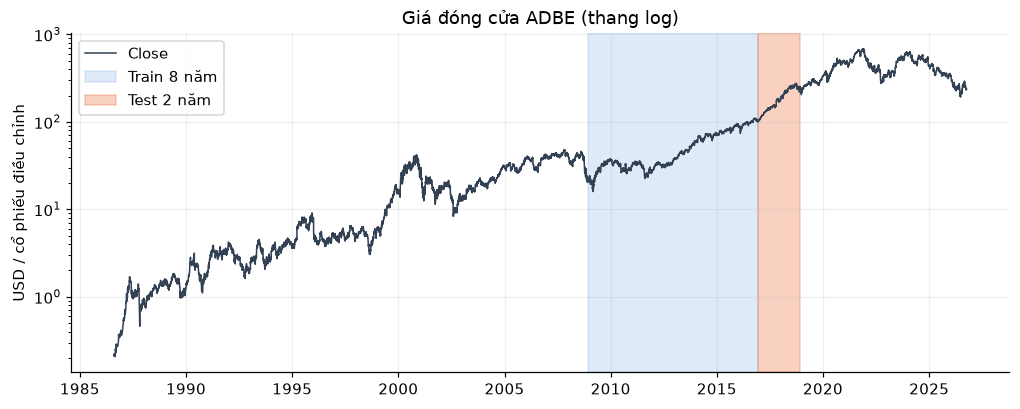

In [3]:
split = config.tracks[TRACK]
fig, ax = plt.subplots()
ax.semilogy(prices.Date, prices.Close, color='#334155', lw=1, label='Close')
ax.axvspan(pd.Timestamp(split.train_start), pd.Timestamp(split.train_end), color=COLORS[0], alpha=.15, label='Train 8 năm')
ax.axvspan(pd.Timestamp(split.test_start), pd.Timestamp(split.test_end), color=COLORS[1], alpha=.3, label='Test 2 năm')
ax.set(title='Giá đóng cửa ADBE (thang log)', ylabel='USD / cổ phiếu điều chỉnh')
ax.legend(loc='upper left')
plt.show()

## 2. Luật giao dịch và chia train/test

`load_track` kiểm tra train đúng 8 năm, test đúng 2 năm, test đứng sau train và hai tập không trùng ngày nào. Trong train, 7 năm đầu (fit) dùng để học và năm cuối (validation) dùng để chọn checkpoint cho biến thể CEM chỉ báo.

In [4]:
track = load_track(config, TRACK)
pd.Series(vars(config.rules), name='giá trị').to_frame()

,giá trị
initial_cash,100000.0
buy_min,0.35
buy_max,0.73
sell_min,0.13
sell_max,0.82
fee_rate,0.04
idle_limit,21
idle_penalty,4376.0
loss_assets,1000.0
loss_cash,-5000.0


In [5]:
pd.DataFrame({period: info for period, info in track.describe().items() if isinstance(info, dict)}).T

,first_session,last_session,sessions
fit,2008-12-05,2015-12-04,1762
validation,2015-12-07,2016-12-02,251
train,2008-12-05,2016-12-02,2013
test,2016-12-05,2018-12-04,504


## 3. Môi trường

- **Action space:** 7 hành động rời rạc. Số cổ phiếu được làm tròn thành số nguyên trong giới hạn BUY/SELL; lệnh không khả thi bị mask.
- **Observation:** 18 chiều, gồm 12 đặc trưng giá đến phiên trước và 6 thông tin tài khoản/thời gian.
- **Reward:** log(E_t / E_(t−1)), trong đó phí và phạt đã làm giảm E.
- **Terminated:** khi thắng (≥ 1 triệu USD) hoặc thua (tài sản < 1.000 USD hoặc tiền mặt ≤ −5.000 USD). **Truncated:** khi hết dữ liệu.

In [6]:
env = TradingEnv(track.market, *track.ranges['train'], config.rules)
obs, _ = env.reset()
print('Actions:     ', dict(enumerate(ACTIONS)))
print('Observation: ', FEATURE_NAMES + OBSERVATION_NAMES)
print('obs.shape =', obs.shape, '| action_mask =', env.action_mask().astype(int))

Actions:      {0: 'hold', 1: 'buy_min', 2: 'buy_mid', 3: 'buy_max', 4: 'sell_min', 5: 'sell_mid', 6: 'sell_max'}
Observation:  ['return_1', 'return_5', 'return_20', 'return_60', 'return_252', 'ma_20', 'ma_60', 'ma_200', 'rsi_14', 'volatility_20', 'relative_price_ma252', 'drawdown_252', 'exposure', 'idle_fraction', 'log_assets', 'assets_drawdown', 'log_previous_high', 'years']
obs.shape = (18,) | action_mask = [1 1 1 1 0 0 0]


Chạy thử vài bước: mua 73% tiền mặt, giữ, bán 13% cổ phiếu, rồi không giao dịch 21 phiên liên tiếp để thấy phạt 4.376 USD.

In [7]:
for action in [3, 0, 4] + [0] * 21:
    obs, reward, terminated, truncated, info = env.step(action)
columns = ['Date', 'trade', 'quantity', 'execution_price', 'fee', 'penalty', 'idle', 'cash', 'shares', 'assets', 'reward']
pd.DataFrame(env.history)[columns].iloc[[0, 1, 2, 22, 23]]

,Date,trade,quantity,execution_price,fee,penalty,idle,cash,shares,assets,reward
0,2008-12-05,buy,3370.0,21.66,2919.7680,0.0,0,24086.0320,3370.0,97686.832000,-0.023403
1,2008-12-08,hold,0.0,0.00,0.0000,0.0,1,24086.0320,3370.0,101596.032000,0.039238
2,2008-12-09,sell,439.0,23.92,420.0352,0.0,0,34166.8768,2931.0,104276.396800,0.026041
22,2009-01-08,hold,0.0,0.00,0.0000,0.0,20,34166.8768,2931.0,105624.653869,-0.011862
23,2009-01-09,hold,0.0,0.00,0.0000,4376.0,0,29790.8768,2931.0,101600.376800,-0.038845


## 4. Baseline: giữ cổ phiếu và tránh phạt

Baseline mua tối đa khi tỷ trọng cổ phiếu dưới 98%, và chỉ đặt lệnh nhỏ nhất khi sắp bị phạt.

In [8]:
_, baseline = run_episode(PenaltyAwareHold(), TradingEnv(track.market, *track.ranges['train'], config.rules))
pd.Series(baseline, name='baseline (train)').to_frame()

,baseline (train)
final_assets,382862.45089
peak_assets,428748.90493
peak_date,2016-10-24
score_ratio_peak,0.428749
cumulative_reward,1.342506
trades,125
total_fees,34799.016274
total_penalty,0.0
max_drawdown,-0.406082
sessions,2013


## 5. Huấn luyện CEM (chỉ dùng dữ liệu train)

`train_track` lần lượt thực hiện:

1. CEM chỉ báo fit trên 7 năm, chọn checkpoint theo tài sản cuối của năm validation → `cem_validation`.
2. CEM chỉ báo trên đủ 8 năm, chọn theo đỉnh tài sản train → `cem_train_peak`.
3. CEM theo thời gian (33 mốc tỷ trọng) trên 8 năm → `cem_temporal` (model chính).
4. Tỷ trọng tiếp tục, chọn bằng lưới trên toàn bộ 8 năm train → `cem_temporal_continuation` (biến thể).

Mỗi nhánh chạy 3 seed; mỗi seed gồm 35 thế hệ CEM.

In [9]:
start = time.time()
train_track(config, TRACK, OUTPUT)
print(f'Huấn luyện xong sau {time.time() - start:.0f} giây')

[consecutive] indicator CEM on fit, seed 7
[consecutive] indicator CEM on fit, seed 42
[consecutive] indicator CEM on fit, seed 123
[consecutive] indicator CEM on train, seed 7
[consecutive] indicator CEM on train, seed 42
[consecutive] indicator CEM on train, seed 123
[consecutive] temporal CEM on train, seed 7
[consecutive] temporal CEM on train, seed 42
[consecutive] temporal CEM on train, seed 123
Huấn luyện xong sau 200 giây


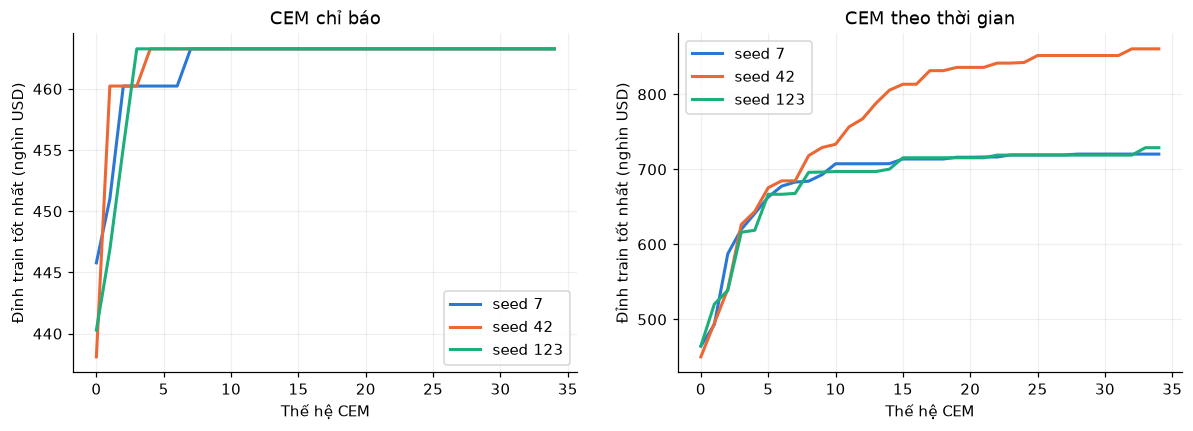

{'source': 'constant-exposure grid on the training period only', 'continuation_exposure': 0.99999, 'continuation_logit': 11.51291546492478, 'grid': [{'exposure': 0.0, 'peak': 100311.81826408001, 'final': 84695.84347559998, 'lost': False, 'fitness': -0.005347518318853895}, {'exposure': 0.05, 'peak': 100571.87083728, 'final': 93172.58296976006, 'lost': False, 'fitness': 0.0018814636170817354}, {'exposure': 0.1, 'peak': 100571.87083728, 'final': 93172.58296976006, 'lost': False, 'fitness': 0.0018814636170817354}, {'exposure': 0.15, 'peak': 102953.74184460001, 'final': 100952.71694408006, 'lost': False, 'fitness': 0.028128217012916117}, {'exposure': 0.2, 'peak': 102953.74184460001, 'final': 100952.71694408006, 'lost': False, 'fitness': 0.028128217012916117}, {'exposure': 0.25, 'peak': 104910.95234368, 'final': 93181.75105591994, 'lost': False, 'fitness': 0.04201373048358753}, {'exposure': 0.3, 'peak': 118785.51855112004, 'final': 115441.22717104002, 'lost': False, 'fitness': 0.170721417942

In [10]:
learning = track_dir(OUTPUT, TRACK) / 'learning'
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name, title in zip(axes, ['indicator_train', 'temporal_train'], ['CEM chỉ báo', 'CEM theo thời gian']):
    log = pd.read_csv(learning / f'{name}.csv')
    for (seed, g), color in zip(log.groupby('seed'), COLORS):
        ax.plot(g.generation, g.best_peak / 1000, color=color, lw=2, label=f'seed {seed}')
    ax.set(title=title, xlabel='Thế hệ CEM', ylabel='Đỉnh train tốt nhất (nghìn USD)')
    ax.legend()
plt.show()
json.loads((learning / 'continuation.json').read_text(encoding='utf-8'))

## 6. Tái lập: model vừa train so với model đã nộp

CEM dùng seed cố định, nên huấn luyện lại với ngân sách đầy đủ phải cho ra đúng các tham số (θ, continuation_logit) của model đã nộp trong `outputs/consecutive/models/`. Notebook so sánh nội dung JSON thay vì so từng byte, vì Windows và Linux (Kaggle) ghi ký tự xuống dòng khác nhau.

In [11]:
new_models = track_dir(OUTPUT, TRACK) / 'models'
saved_models = track_dir(OUTPUT_DIR, TRACK) / 'models'
read = lambda p: json.loads(p.read_text(encoding='utf-8'))
same = {p.name: read(p) == read(saved_models / p.name) for p in sorted(new_models.glob('*.json'))}
print(json.dumps(same, indent=2))
if not QUICK:
    assert all(same.values()), 'model vừa train phải trùng model đã nộp'

{
  "cem_temporal.json": true,
  "cem_temporal_continuation.json": true,
  "cem_train_peak.json": true,
  "cem_validation.json": true
}


## 7. Đánh giá train và test (load model đã lưu, không train lại)

Mỗi episode bắt đầu từ 100.000 USD tiền mặt. Có hai kịch bản giá bán: High (`sell_high`) và Close (`sell_close`).

In [12]:
summary = evaluate_track(config, TRACK, OUTPUT)
columns = ['model', 'period', 'peak_assets', 'final_assets', 'cumulative_reward', 'trades', 'total_fees', 'end_reason']
summary.query("scenario == 'sell_high'")[columns].round(2)

      track                     model period   peak_assets  final_assets  end_reason
consecutive        penalty_aware_hold  train 428748.904930 382862.450890 end_of_data
consecutive            cem_validation  train 460231.874818 415186.679816 end_of_data
consecutive            cem_train_peak  train 463271.935404 417658.622808 end_of_data
consecutive              cem_temporal  train 860523.739536 770544.617674 end_of_data
consecutive cem_temporal_continuation  train 860523.739536 770544.617674 end_of_data
consecutive        penalty_aware_hold   test 253645.537403 230625.490481 end_of_data
consecutive            cem_validation   test 249773.477829 230503.998603 end_of_data
consecutive            cem_train_peak   test 255494.330695 234553.068814 end_of_data
consecutive              cem_temporal   test 254241.926029 233742.791998 end_of_data
consecutive cem_temporal_continuation   test 254241.926029 233742.791998 end_of_data


,model,period,peak_assets,final_assets,cumulative_reward,trades,total_fees,end_reason
0,penalty_aware_hold,train,428748.90,382862.45,1.34,125,34799.02,end_of_data
1,cem_validation,train,460231.87,415186.68,1.42,96,20550.50,end_of_data
2,cem_train_peak,train,463271.94,417658.62,1.43,100,21167.93,end_of_data
3,cem_temporal,train,860523.74,770544.62,2.04,132,71112.55,end_of_data
4,cem_temporal_continuation,train,860523.74,770544.62,2.04,132,71112.55,end_of_data
10,penalty_aware_hold,test,253645.54,230625.49,0.84,36,13150.34,end_of_data
11,cem_validation,test,249773.48,230504.00,0.84,24,7469.40,end_of_data
12,cem_train_peak,test,255494.33,234553.07,0.85,26,7599.97,end_of_data
13,cem_temporal,test,254241.93,233742.79,0.85,28,9745.45,end_of_data
14,cem_temporal_continuation,test,254241.93,233742.79,0.85,28,9745.45,end_of_data


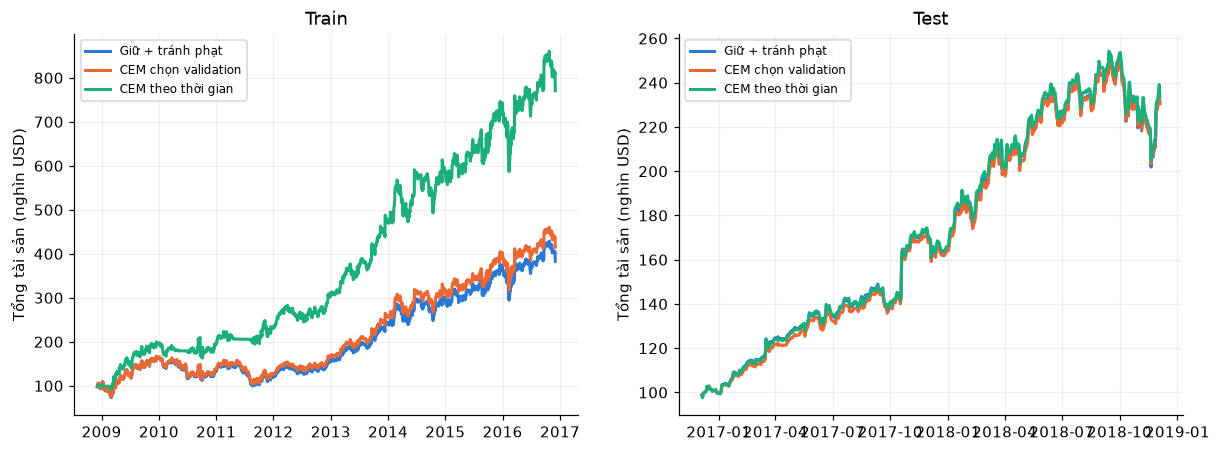

In [13]:
histories = track_dir(OUTPUT, TRACK) / 'histories'
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, period in zip(axes, ['train', 'test']):
    for model, color in zip(['penalty_aware_hold', 'cem_validation', 'cem_temporal'], COLORS):
        h = pd.read_csv(histories / history_name(model, period, 'sell_high'), parse_dates=['Date'])
        ax.plot(h.Date, h.assets / 1000, color=color, lw=2, label=LABELS[model])
    ax.set(title=period.capitalize(), ylabel='Tổng tài sản (nghìn USD)')
    ax.legend(loc='upper left', fontsize=8)
plt.show()

## 8. Bonus: test 2 năm bằng `load_policy` + `predict`

Đây là vòng lặp agent–môi trường viết tường minh: nạp file model, rồi mỗi phiên gọi `model.predict(obs, account, action_mask)` và `env.step(action)`. Hash của file model được so trước và sau để chứng minh không có cập nhật nào.

In [14]:
path = track_dir(OUTPUT, TRACK) / 'models/cem_temporal.json'
hash_before = hashlib.sha256(path.read_bytes()).hexdigest()
model = load_policy(path, config.rules)

env = TradingEnv(track.market, *track.ranges['test'], config.rules)
obs, info = env.reset()
while not env.done:
    action = model.predict(obs, env.account, env.action_mask())
    obs, reward, terminated, truncated, info = env.step(action)

assert hashlib.sha256(path.read_bytes()).hexdigest() == hash_before
print(f"Tổng tài sản:      {info['assets']:,.2f} USD")
print(f"Cumulative reward: {env.reward_sum:.6f}")
print(f"Dừng ngày {info['Date']}, lý do: {info['reason']}, sau {len(env.history)} phiên")

Tổng tài sản:      233,742.79 USD
Cumulative reward: 0.849051
Dừng ngày 2018-12-04, lý do: end_of_data, sau 504 phiên


In [15]:
test_log = pd.DataFrame(env.history)
trades = test_log[test_log.quantity > 0]
print(f"{(trades.trade == 'buy').sum()} lệnh mua, {(trades.trade == 'sell').sum()} lệnh bán, "
      f"tổng phí {test_log.fee.sum():,.2f} USD, tổng phạt {test_log.penalty.sum():,.2f} USD")
trades[['Date', 'trade', 'quantity', 'execution_price', 'fee', 'cash', 'shares', 'assets']].head(8)

25 lệnh mua, 3 lệnh bán, tổng phí 9,745.45 USD, tổng phạt 0.00 USD


,Date,trade,quantity,execution_price,fee,cash,shares,assets
0,2016-12-05,buy,728.0,100.150002,2916.368058,24174.430486,728.0,98808.988302
1,2016-12-06,buy,172.0,102.519997,705.337579,5835.653422,900.0,97626.651622
22,2017-01-06,buy,20.0,106.019997,84.815998,3630.437485,920.0,103386.037485
43,2017-02-07,buy,12.0,114.830002,55.118401,2197.359060,932.0,109554.440924
64,2017-03-09,buy,7.0,120.660004,33.784801,1318.954231,939.0,114243.096109
85,2017-04-07,buy,4.0,130.220001,20.835200,777.239027,943.0,123999.047141
106,2017-05-09,buy,3.0,135.389999,16.246800,354.822230,946.0,128651.337500
127,2017-06-08,buy,1.0,143.770004,5.750800,205.301426,947.0,136544.892373


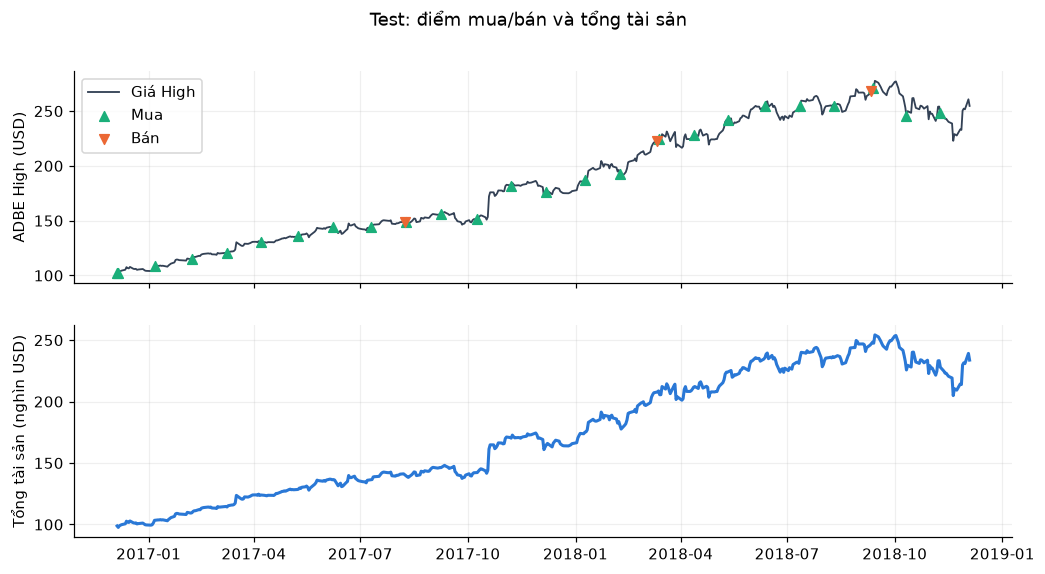

In [16]:
dates = pd.to_datetime(test_log.Date)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(dates, test_log.mark_price, color='#334155', lw=1.2, label='Giá High')
for kind, marker, color, label in [('buy', '^', COLORS[2], 'Mua'), ('sell', 'v', COLORS[1], 'Bán')]:
    m = test_log.trade == kind
    axes[0].scatter(dates[m], test_log.mark_price[m], marker=marker, color=color, s=40, label=label, zorder=3)
axes[0].set_ylabel('ADBE High (USD)')
axes[0].legend(loc='upper left')
axes[1].plot(dates, test_log.assets / 1000, color=COLORS[0], lw=2)
axes[1].set_ylabel('Tổng tài sản (nghìn USD)')
fig.suptitle('Test: điểm mua/bán và tổng tài sản')
plt.show()

Cùng model, nếu bán theo giá Close thay vì High:

In [17]:
summary.query("model == 'cem_temporal' and scenario == 'sell_close'")[columns].round(2)

,model,period,peak_assets,final_assets,cumulative_reward,trades,total_fees,end_reason
8,cem_temporal,train,834621.82,752439.19,2.02,131,62055.45,end_of_data
18,cem_temporal,test,253531.58,233078.25,0.85,28,9685.61,end_of_data


## 9. Replay trên các giai đoạn 2020–2024 (đánh giá hạn chế)

Dùng nguyên model đã train trên 2008–2016, không train lại. Kết quả cho thấy chính sách phụ thuộc mạnh vào xu hướng thị trường của giai đoạn test.

In [18]:
replay = replay_windows(config, OUTPUT)
replay.query("model == 'cem_temporal' and scenario == 'sell_high'")[
    ['window_start', 'window_end', 'final_assets', 'peak_assets', 'return_pct', 'trades']].round(2)

,window_start,window_end,final_assets,peak_assets,return_pct,trades
3,2020-01-01,2022-01-01,158000.95,193670.85,58.00,29
13,2021-01-01,2023-01-01,61635.53,131060.90,-38.36,30
23,2022-01-01,2024-01-01,95734.02,100951.58,-4.27,31
33,2023-01-01,2025-01-01,119560.85,175020.96,19.56,30


## 10. Kiểm chứng tự động

Kiểm tra lại toàn bộ log: giới hạn lệnh, phí, phạt, kế toán từng phiên, giá khớp, chia dữ liệu, tính nhân quả của observation, sự khớp nhau giữa mô phỏng đơn và mô phỏng vector, replay bằng load/predict, và hash model.

In [19]:
result = verify(config, OUTPUT, tracks=[TRACK])

[consecutive] verified
{
  "status": "PASS",
  "checks": [
    "8-year train and 2-year test calendar windows, zero overlap, train before test",
    "buy orders within 35-73% of cash, sell orders within 13-82% of shares, whole shares",
    "4% fee on both sides; cash, shares and assets reconcile every session",
    "penalty exactly after 21 idle sessions; failed orders do not reset the counter",
    "buy fills at previous High, sell fills at today High/Close",
    "cumulative reward equals the sum of rewards; only the last row ends the episode",
    "observations unaffected by current or future prices",
    "single-episode env equals the vectorized simulator",
    "load/predict replay reproduces stored summaries",
    "model files unchanged by evaluation"
  ],
  "audited_histories": 60
}


## 11. Kết quả cuối

In [20]:
main = summary.query("model == 'cem_temporal' and scenario == 'sell_high'").set_index('period')
pd.DataFrame({'Tổng tài sản (USD)': main.peak_assets.map('{:,.2f}'.format),
              'Tỷ lệ so với 1M': (100 * main.score_ratio_peak).map('{:.2f}%'.format),
              'Cumulative reward': main.cumulative_reward.round(6),
              'Ngày dừng': main.peak_date,
              'Kết thúc': main.end_reason})

,Tổng tài sản (USD),Tỷ lệ so với 1M,Cumulative reward,Ngày dừng,Kết thúc
period,,,,,
train,"860,523.74",86.05%,2.041927,2016-10-24,end_of_data
test,"254,241.93",25.42%,0.849051,2018-09-14,end_of_data
